In [1]:
%matplotlib inline
import numpy as np
import random as rnd
import matplotlib.pyplot as plt
import time
from scipy.stats import wilcoxon

PART ONE

Part One aims to implement and evaluate a baseline local search algorithm using a Hill-Climber approach. This will be conducted using Instance One, this contains 28 models and 2 storage constraints. Each model has an associated utility and two storage capacities. This is a multi-dimensional knapsack problem as the objective is to select a combination of models to maximise the total utility without exceeding either storage requirement. 

In [2]:
def load_workload_instance(file_path):
    """
    Loads a hardware-constrained workload allocation dataset.
    
    Parameters:
        file_path (str): Path to the dataset plain text file (.txt).
        
    Returns:
        n (int): Number of candidate AI models.
        m (int): Number of hardware resource constraints.
        utilities (np.ndarray): 1D array of shape (n,) containing model utility scores (p_j).
        demands (np.ndarray): 2D array of shape (m, n) containing resource consumption demands (r_{i,j}).
        capacities (np.ndarray): 1D array of shape (m,) containing hardware capacity limits (b_i).
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()
        
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")
        
    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2
    
    # Model utility scores (length n)
    utilities = np.array([float(x) for x in tokens[idx : idx + n]])
    idx += n
    
    # Resource demand matrix (shape m x n)
    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx : idx + n]]
        idx += n
        
    # Maximum hardware capacity limits (length m)
    capacities = np.array([float(x) for x in tokens[idx : idx + m]])
    
    return n, m, utilities, demands, capacities


if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n28_m2.txt"
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        print("=== Dataset Ingestion Summary ===")
        print(f"Number of candidate models (n) : {n}")
        print(f"Number of resource bounds (m)  : {m}")
        print(f"Utility scores shape (p_j)     : {utilities.shape}")
        print(f"Resource demands shape (r_ij)  : {demands.shape}")
        print(f"Capacity limits (b_i)          : {capacities}")
    except FileNotFoundError:
        print(f"Please provide a valid path to '{sample_file}'.")


=== Dataset Ingestion Summary ===
Number of candidate models (n) : 28
Number of resource bounds (m)  : 2
Utility scores shape (p_j)     : (28,)
Resource demands shape (r_ij)  : (2, 28)
Capacity limits (b_i)          : [500. 500.]


Instance one was loaded and checked that there were 28 total models and 2 storage requirements. Each storage capacity is 500 and each model has a utility, and two storage requirements.

Creation of Fractional Demand (how much of each capacity each model uses), Model Utility/Capacity ratio, and an ordered list of models from best ratio to least for use in repair function later on.

In [3]:
#Calculates the total fraction of each capacity required by each model
fractionDemand = (demands / capacities[:, None]).sum(axis = 0)
#Calculates the priority sorting ratio by dividing a models utility by capacity demand
ratio = utilities / fractionDemand
#Sorts models by priority in descending order(model with highest utility-to-demand first)
modelsByRatio = list(np.argsort(-ratio))

Solution Representation
A solution is represented using a binary vector where each position corresponds to a model (28 positions for Instance One). A value of 1 indicates a model is deployed (selected) whilst a value of 0 indicates this is excluded (undeployed).

Objective
The objective for Part One is to maximise total utility whilst satisfying both resource constraints. As such solutions are evaluated in relation to total utility with an acceptable flag to signify when they are within resource constraints. 

Initial Solution Creation Function

In [4]:
def generateSolution(size, proportion):
    """ 
    function to create a random binary solution of size = size
    """
    solution = rnd.choices([0,1], weights = [proportion, 1 - proportion], k = size)
    return solution

To evaluate the total utility is calculated by summing the utilities of all deployed models. The total storage demand for each constraint is also found by summing the storage requirements of all deployed models. If neither storage capacity is exceeded then the solution is considered to be feasible. 

Solution Evaluation Function

In [5]:
def evaluate(sol, storageMax, utilities, demands):
    """
    Evaluates a solution (sol) against storageMax (the capacities for the models) returning the total utility of the solution,
    capacity used for each capacity, and whether the solution is under all capacity limits.
    Input: Solution as a binary array and capacities as an array.
    Output: the total utility score, the total capacities used and whether the solution is under all allowed capacities. 
    """
    
    numItems = len(sol)
    numCapacities = len(storageMax)

    totalUtilities = sum( sol[i] * utilities [i] for i in range (numItems))
    #totalCapacities created to hold values for the different types of capacity
    totalCapacities = []
    
    for j in range(numCapacities):
        capacity = sum(sol[i] * demands[j][i] for i in range (numItems))
        totalCapacities.append(capacity)

    underCapacity = all(totalCapacities [j] <= storageMax [j] for j in range(numCapacities))
        
    
    return totalUtilities, totalCapacities, underCapacity

A starting solution is created with each model having a 10% chance of being deployed. To make sure the starting solution is feasible the solution is evaluated against the storage constraints. If the solution is infeasible, another random solution is generated until a feasible starting pont is found. This ensure that the Hill-Climber always begins from a valid solution.

Starting Solution Creation Function for hillClimber

In [6]:
def startingSolution (size, storageMax, utilities, storageReqs):
    """
    Creates a random acceptable solution, retrying until solution satifies all storage maximums.
    Input:Size of required solution (size), Maximum Storage Capacities (storageMax), utilities of models, and storageReqs of models.
    Output: The Solution, Utility Value, Resource Usage and number of evalutions taken to form an acceptable solution.
    """
    used = 0
    while True:
        solution = generateSolution(size, 0.9)
        utility, demand, acceptable = evaluate(solution, storageMax, utilities, storageReqs)
        used += 1
        if acceptable:
            return solution, utility, demand, used

Mutation Functions

Two mutation functions were used in Part One:

Bit Flip: This mutation selects a random position in the solution and alters a single model from 0 to 1 or 1 to 0. This mutation can only effect a single model in the solution each time it is called.

Swap: This mutation selects a currently deployed model (1) and a currently undeployed model and exchanges their status. This keeps the number of selected models constant and only effects two models in the solution each time it is called. 

Neighbour (Bit Flip) Creation Function

In [7]:
def createNeighbour(sol):
    """
    Takes in a solution (sol) and creates a bit flip mutation (one model change) of the solution.
    Input: A given solution
    Output: A bit flip mutation (neighbour) solution for the solution given.
    """
    neighbour = sol.copy()
    i = rnd.randint(0, len(sol) - 1)
    neighbour [i] = 0 if sol[i] == 1 else 1
    return neighbour

Swap Mutation Creation Function

In [8]:
def swapMutation(sol):
    """
    Takes in a solution (sol) and creates a swap mutation of the solution. This is where one deployed model is
    undeployed and one undeployed model becomes deployed (two model change). Number of deployed models remains the same.
    If all models deployed or no models deployed then the solution remains unchanged.
    Input: A given solution
    Output: A swap mutated copy for the solution given.
    """
    mutant = sol.copy()
    size = len(sol)
    active = [i for i in range(size) if sol[i] == 1]
    dormant = [i for i in range(size) if sol[i] == 0]
    if active and dormant:
        mutant[rnd.choice(active)] = 0
        mutant[rnd.choice(dormant)] = 1
    return mutant

Repair
A solution generated may exceed one or more of the resource constraints and therefore no longer be a good candidate. Rather than losing this solution repair aims to restore feasibility by removing models until the resource consumption is back within capacities. This approach is inspired by the feasibility repair method proposed by Chu and Beasley[1]. 

Repair Solution Creation Function

In [9]:
def repairSolution(sol, storageMax, storageReqs, sortedModels):
    """
    Takes in a solution (sol) and makes it acceptable (all capacities equal to or below maximum capacity given. 
    Works in two phases:
    Removal Phase: undeploys models with lowest utility by capacity until each capacity is no longer exceeded.
    Insertion Phase: depoys skipped models with best utility by capacity ratios that still fit within each capacity.
    Input: A given solution
    Output: A repaired copy of the solution that is within all capacity limits. 
    """
    sol = sol.copy()
    usage = np.dot(storageReqs, sol)
    for j in sortedModels[::-1]:
        if np.all(usage <= storageMax):
            break
        if sol[j] == 1:
            sol [j] = 0
            usage = usage - storageReqs [:, j]
    for j in sortedModels:
        if sol [j] == 0 and np.all(usage + storageReqs[:, j] <= storageMax):
            sol[j] = 1
            usage = usage + storageReqs [:, j]
    return sol
                                   
            
        

The Hill-Climber starts from a feasible solution and then evaluates neighbouring solutions to find improvements on the overall utility. When an improvement is found, that is within the capacity contraints this is taken forward as the new solution. This is an iterative process where the search moves towards locally better solutions. This can lead to the algorithm becoming trapped in a local optimum with all neighbours being worse than a given solution even though a better solution exists. 
The swap mutator is off by default but when engaged activates half of the time instead of the bit flip mutator. This allows for a greater degree of variation in the solutions. 
The repair function is not used by default but when active it takes in the proposed new solution and turns insfeasible solutions feasible. It also improves feasible solutions by allocating models until a capacity is reached. 
Finally, a restart option is available to allow the function to escape when it is trapped at a local maximum. This works by taking a completely new solution and using it for the Hill-Climber. The trace is only appended if the new solution has a better utility than the current best utility. 

Hill-Climber Function

In [10]:
def hillClimber(maxEvals, storageMax , storageReqs, utilities, sortedModel, swap = False, restartAfter = None, repair = False):
    """
    Hill-Climber function with optional swap mutation, optional restart and optional repair. Stops after maxEval number of evaluations
    by counting every call to the evaluate function (including starting solutions).
    Inputs: Max number of evaluations, storage capacities, storage demands, utilities and models ranked by ratio
    Output: Best utility, it's resource usage, the best solution and trace of best utility after each evaluation
    """
    size = len(utilities)
    solution, utility, demand, used = startingSolution(size, storageMax, utilities, storageReqs)
    evals = used
    bestUtility, bestDemand = utility, demand
    bestSolution = solution.copy()
    trace = [bestUtility] * used
    stuck = 0
    
    while evals < maxEvals:
        if swap and rnd.random() < 0.5:
            neighbour = swapMutation(solution)
        else:
            neighbour = createNeighbour(solution)

        if repair:
            neighbour = repairSolution(neighbour, storageMax, storageReqs, sortedModel)
        neighbourUtility, neighbourDemand, neighbourAcceptable = evaluate(neighbour, storageMax, utilities, storageReqs)
        evals += 1
        if neighbourAcceptable and neighbourUtility >= utility:
                if neighbourUtility > utility:
                    stuck = 0
                else:
                    stuck += 1
                solution = neighbour.copy()
                utility = neighbourUtility
                demand = neighbourDemand
        else:
            stuck += 1
        if utility > bestUtility:
            bestUtility, bestDemand = utility, demand
            bestSolution = solution.copy()
        if restartAfter is not None and stuck >= restartAfter and evals < maxEvals:
            solution, utility, demand, used = startingSolution(size, storageMax, utilities, storageReqs)
            evals += used
            if utility > bestUtility and evals <= maxEvals :
                bestUtility, bestDemand = utility, demand
                bestSolution = solution.copy()
            trace.extend([bestUtility] * used)
            stuck = 0
    
        trace.append(bestUtility)
    return bestUtility, bestDemand, bestSolution, trace[:maxEvals]

Check that Repair Always Gives an Acceptable Solution.

In [56]:
for i in range(10000):
    newSolution = generateSolution(n,0.5)
    assert evaluate(repairSolution(newSolution, capacities, demands, modelsByRatio), capacities, utilities, demands) [2]
print("Repair always gives an acceptable solution")

Repair always gives an acceptable solution


Swap always keeps total number of deployed models the same and only changes 2. Expect both sums to come back equal and 2 values to be different.

In [57]:
solutionA = generateSolution(n, 0.9)
solutionB = swapMutation(solutionA)
print(sum(solutionA),sum(solutionB))
print(sum(value != value2 for value, value2 in zip(solutionA, solutionB)))

4 4
2


Hill-Climber check to make sure result acceptable, trace of correct length, trace never decreases, and is repeatable

In [13]:
rnd.seed(1); np.random.seed(1)
bestHill, usageHill, solutionHill, traceHill = hillClimber(1000, capacities, demands, utilities, modelsByRatio, True, 25, True)
print(evaluate(solutionHill, capacities, utilities, demands)[2], len(traceHill), np.all(np.diff(traceHill) >= 0))


True 1000 True


Check that random seeds returning the same details

In [14]:
rnd.seed(7); np.random.seed(7)
run1= hillClimber(1000, capacities, demands, utilities, modelsByRatio, True, 25, True)
rnd.seed(7); np.random.seed(7)
run2= hillClimber(1000, capacities, demands, utilities, modelsByRatio, True, 25, True)
print("repeatable:", run1 == run2)

repeatable: True


Part One Experiment
To evaluate the peerformance of the Hill-Climbing algorithm, a series of experiments were conducted using Instance One.
Six different configurations were tested to investigate the effect of different mutation strategies and feasibility handling:
1. Bit Flip Only.
2. Bit Flip with periodic restarts.
3. Bit Flip and Swap Mutation.
4. Bit Flip and Swap Mutation with periodic restarts.
5. Bit Flip and Swap Mutation with repair.
6. Bit Flip and Swap Mutation with periodic restarts and repair.

Each configuration was evaluated across 30 runs using random seed 42 as the starting point. 
Performance was assessed using minimum utility, maximum utility, mean utility, standard deviation and time across runs.
This experiemnet aims to investigate the effect of differing mutation functions, set restarts and feasibility repair on the performance of the baseline Hill-Climber algorithm.

In [15]:
def runExperiment (storageMax , storageReqs, utilities, sortedModel, swap = False, restartAfter = None, repair = False, numRuns = 30, maxEvals = 1000):
    """
    Runes the Hill-Climber numRuns times, each from its own seed (starting seed set to 42 for replicability) and each time with the same maximum number
    of evaluations so that comparisons are fair.
    Input: Storage capacities, storage demands, utilities and models ranked by ratio, swap switch, restart switch, repair switch, number of runs
    and maximum number of evaluations.
    Output: arrays for best utilities, traces, best solutions, and run times
    """
    bestList, traces, times, solutions = [], [], [], []
    for run in range(numRuns):
        np.random.seed (42 + run)
        rnd.seed(42 + run)
        start = time.time()
        best, usage, solution, trace = hillClimber(maxEvals,storageMax, storageReqs, utilities, sortedModel, swap, restartAfter, repair)
        times.append(time.time() - start)
        bestList.append(best)
        traces.append(trace)
        solutions.append(solution)
    return np.array(bestList), np.array(traces), np.array(solutions), np.array(times)
        
        
        

In [16]:
for restart in [1, 2, 5, 10, 15 , 20, 25, 50, 100, 200, 500, None]:
    findings = runExperiment(capacities, demands, utilities, modelsByRatio, swap = False, restartAfter = restart)[0]
    print(f"Restart After = {restart}: Mean = {findings.mean():.0f} Min = {findings.min():.0f} Standard Deviation = {findings.std():.0f}")

Restart After = 1: Mean = 101810 Min = 87263 Standard Deviation = 8688
Restart After = 2: Mean = 108698 Min = 98273 Standard Deviation = 5983
Restart After = 5: Mean = 111203 Min = 100246 Standard Deviation = 5929
Restart After = 10: Mean = 109720 Min = 94678 Standard Deviation = 6160
Restart After = 15: Mean = 111423 Min = 101587 Standard Deviation = 5378
Restart After = 20: Mean = 108660 Min = 97094 Standard Deviation = 5452
Restart After = 25: Mean = 107223 Min = 94222 Standard Deviation = 6714
Restart After = 50: Mean = 105878 Min = 91686 Standard Deviation = 7463
Restart After = 100: Mean = 103667 Min = 80711 Standard Deviation = 9287
Restart After = 200: Mean = 100827 Min = 79447 Standard Deviation = 10962
Restart After = 500: Mean = 90544 Min = 69845 Standard Deviation = 11285
Restart After = None: Mean = 81097 Min = 49239 Standard Deviation = 16989


In [17]:
for restart in [1, 2, 5, 10, 15 , 20, 25, 50, 100, 200, 500, None]:
    findings = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, restartAfter = restart)[0]
    print(f"Restart After = {restart}: Mean = {findings.mean():.0f} Min = {findings.min():.0f} Standard Deviation = {findings.std():.0f}")

Restart After = 1: Mean = 98035 Min = 85742 Standard Deviation = 6296
Restart After = 2: Mean = 111498 Min = 96842 Standard Deviation = 7485
Restart After = 5: Mean = 117379 Min = 105907 Standard Deviation = 5241
Restart After = 10: Mean = 121594 Min = 114076 Standard Deviation = 3913
Restart After = 15: Mean = 119318 Min = 110747 Standard Deviation = 4651
Restart After = 20: Mean = 120423 Min = 108495 Standard Deviation = 4669
Restart After = 25: Mean = 121092 Min = 106973 Standard Deviation = 4529
Restart After = 50: Mean = 119418 Min = 105722 Standard Deviation = 5503
Restart After = 100: Mean = 119362 Min = 107415 Standard Deviation = 5787
Restart After = 200: Mean = 117595 Min = 109303 Standard Deviation = 5223
Restart After = 500: Mean = 113997 Min = 89335 Standard Deviation = 8245
Restart After = None: Mean = 112112 Min = 89335 Standard Deviation = 8756


In [18]:
for restart in [1, 2, 5, 10, 15 , 20, 25, 50, 100, 200, 500, None]:
    findings = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, repair = True, restartAfter = restart)[0]
    print(f"Restart After = {restart}: Mean = {findings.mean():.0f} Min = {findings.min():.0f} Standard Deviation = {findings.std():.0f}")

Restart After = 1: Mean = 129807 Min = 128502 Standard Deviation = 638
Restart After = 2: Mean = 129894 Min = 128502 Standard Deviation = 606
Restart After = 5: Mean = 129810 Min = 129283 Standard Deviation = 604
Restart After = 10: Mean = 130246 Min = 129283 Standard Deviation = 608
Restart After = 15: Mean = 130187 Min = 128342 Standard Deviation = 708
Restart After = 20: Mean = 130502 Min = 129283 Standard Deviation = 519
Restart After = 25: Mean = 130584 Min = 129283 Standard Deviation = 435
Restart After = 50: Mean = 130721 Min = 130013 Standard Deviation = 142
Restart After = 100: Mean = 130798 Min = 130723 Standard Deviation = 80
Restart After = 200: Mean = 130814 Min = 130723 Standard Deviation = 79
Restart After = 500: Mean = 130840 Min = 130723 Standard Deviation = 71
Restart After = None: Mean = 130851 Min = 130723 Standard Deviation = 64


In [19]:
for restart in [1, 2, 5, 10, 15 , 20, 25, 50, 100, 200, 500, None]:
    findings = runExperiment(capacities, demands, utilities, modelsByRatio, swap = False, repair = True, restartAfter = restart)[0]
    print(f"Restart After = {restart}: Mean = {findings.mean():.0f} Min = {findings.min():.0f} Standard Deviation = {findings.std():.0f}")

Restart After = 1: Mean = 129700 Min = 128322 Standard Deviation = 822
Restart After = 2: Mean = 129380 Min = 128322 Standard Deviation = 691
Restart After = 5: Mean = 129231 Min = 128322 Standard Deviation = 712
Restart After = 10: Mean = 129151 Min = 128322 Standard Deviation = 879
Restart After = 15: Mean = 128596 Min = 124835 Standard Deviation = 950
Restart After = 20: Mean = 128907 Min = 128322 Standard Deviation = 682
Restart After = 25: Mean = 128718 Min = 128322 Standard Deviation = 685
Restart After = 50: Mean = 128447 Min = 124155 Standard Deviation = 981
Restart After = 100: Mean = 127586 Min = 121880 Standard Deviation = 1924
Restart After = 200: Mean = 125977 Min = 121880 Standard Deviation = 2280
Restart After = 500: Mean = 124533 Min = 121880 Standard Deviation = 2477
Restart After = None: Mean = 123194 Min = 121880 Standard Deviation = 2200


In [20]:
results = {}
results["Flip only"] = runExperiment(capacities, demands, utilities, modelsByRatio)
results["Flip and Restart"] = runExperiment(capacities, demands, utilities, modelsByRatio, restartAfter = 25)
results["Flip and Swap"] = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True)
results["Flip, Swap and Restart"] = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, restartAfter = 25)
results["Flip, Swap and Repair"] = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, repair = True)
results["Flip, Swap, Restart and Repair"] = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, restartAfter = 25, repair = True)


In [21]:
for name, (bestList, traces, solutions, times) in results.items():
    bestValueFound = [int(np.argmax(t == t[-1])) for t in traces]
    print(f"{name:20s} min = {bestList.min():.0f}, max = {bestList.max():.0f}, mean = {bestList.mean():.0f}, median = {np.median(bestList):.0f}"
            f" std = {bestList.std():.0f}, Iterations to best = {np.mean(bestValueFound):.0f}, time = {times.mean():.2f}s")

Flip only            min = 49239, max = 116405, mean = 81097, median = 82922 std = 16989, Iterations to best = 43, time = 0.03s
Flip and Restart     min = 94222, max = 119914, mean = 107223, median = 107996 std = 6714, Iterations to best = 388, time = 0.03s
Flip and Swap        min = 89335, max = 124025, mean = 112112, median = 112922 std = 8756, Iterations to best = 478, time = 0.03s
Flip, Swap and Restart min = 106973, max = 129788, mean = 121092, median = 120910 std = 4529, Iterations to best = 526, time = 0.03s
Flip, Swap and Repair min = 130723, max = 130883, mean = 130851, median = 130883 std = 64, Iterations to best = 446, time = 0.11s
Flip, Swap, Restart and Repair min = 129283, max = 130883, mean = 130584, median = 130723 std = 435, Iterations to best = 387, time = 0.11s


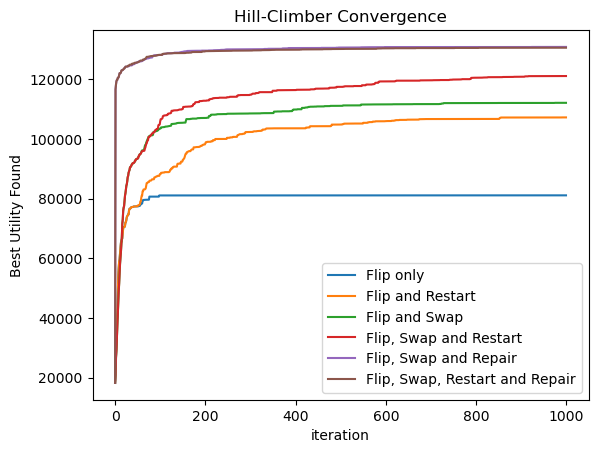

In [22]:
for name, (bestList, traces, solutions, times) in results.items():
    averageTrace = np.mean(traces, axis = 0)
    plt.plot(averageTrace, label = name)
plt.xlabel("iteration")
plt.ylabel("Best Utility Found")
plt.title("Hill-Climber Convergence")
plt.legend()
plt.show()

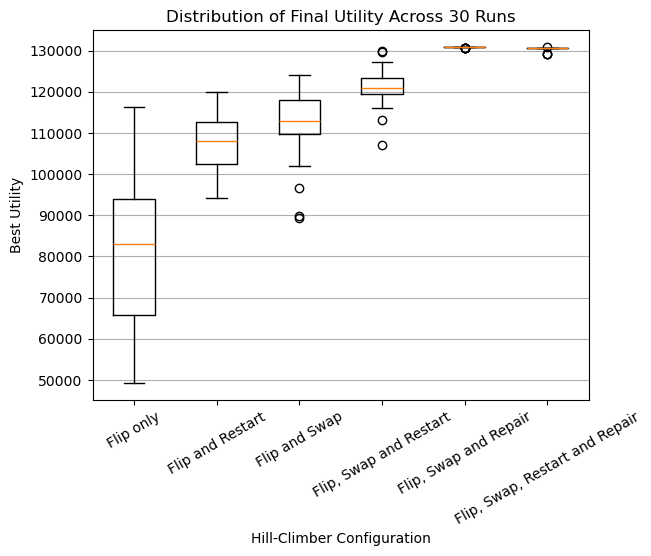

In [23]:
data = [ bestList for bestList, traces, solutions, times in results.values() ]
labels = list(results.keys())
plt.boxplot(data, tick_labels = labels)
plt.xlabel("Hill-Climber Configuration")
plt.ylabel("Best Utility")
plt.title("Distribution of Final Utility Across 30 Runs")
plt.xticks(rotation = 30)
plt.grid(axis="y")
plt.show()

In [24]:
for name, (bestList, traces, solutions, times) in results.items():
    feasibleCount = 0
    for solution in solutions:
        utility, demand, acceptable = evaluate(solution, capacities, utilities, demands)
        if acceptable:
            feasibleCount += 1
    print(f"{name}: {feasibleCount} / {len(solutions)} solutions are feasible")

Flip only: 30 / 30 solutions are feasible
Flip and Restart: 30 / 30 solutions are feasible
Flip and Swap: 30 / 30 solutions are feasible
Flip, Swap and Restart: 30 / 30 solutions are feasible
Flip, Swap and Repair: 30 / 30 solutions are feasible
Flip, Swap, Restart and Repair: 30 / 30 solutions are feasible


PART TWO

Part two aims to implement a population-base metahurisitic to solve the optimisation problem using instance 2. In contrast to part 1 which searches using the current best solution a population-based algorithm maintains multiple solutions simultaneously. This should allow for the exploration of more search space and the identification of higher quality solutions. The objective is to maximise utility across five different storage capacity constraints. 

In [25]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n90_m5.txt"
    try:
        n2, m2, utilities2, demands2, capacities2 = load_workload_instance(sample_file)
        print("=== Dataset Ingestion Summary ===")
        print(f"Number of candidate models (n) : {n2}")
        print(f"Number of resource bounds (m)  : {m2}")
        print(f"Utility scores shape (p_j)     : {utilities2.shape}")
        print(f"Resource demands shape (r_ij)  : {demands2.shape}")
        print(f"Capacity limits (b_i)          : {capacities2}")
    except FileNotFoundError:
        print(f"Please provide a valid path to '{sample_file}'.")

=== Dataset Ingestion Summary ===
Number of candidate models (n) : 90
Number of resource bounds (m)  : 5
Utility scores shape (p_j)     : (90,)
Resource demands shape (r_ij)  : (5, 90)
Capacity limits (b_i)          : [2100. 1100. 3300. 3700. 3600.]


In [26]:
fractionDemand2 = (demands2 / capacities2[:, None]).sum(axis = 0)
ratio2 = utilities2 / fractionDemand2
modelsByRatio2 = list(np.argsort(-ratio2))

In [27]:
def initialisePopulation(popSize, numModels, storageMax, storageReqs, sortedModels):
    """
    Takes in a chosen population size and generates a population of feasible solutions by repairing each solution
    before adding to the population. Returns a population of feasible solutions.
    Input: population size, total number of models, storage capacities, storage demands and a list of models sorted
    by best utility/demand.
    Output: population of feasible situations
    """
    population = []

    for i in range(popSize):
        individual = generateSolution(numModels, 0.5)
        individual = repairSolution(individual, storageMax, storageReqs, sortedModels)
        population.append(individual)
    return population

In [28]:
population = initialisePopulation (100,90, capacities2, demands2, modelsByRatio2)

In [29]:
print("Population Size:", len(population))
print("Individual Size:", len(population[0]))
print("First Individual", population[0])

Population Size: 100
Individual Size: 90
First Individual [1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1]


In [30]:
for individual in population:
    utility, demand, acceptable = evaluate(individual, capacities2, utilities2, demands2)
    assert acceptable
print("All individuals are feasible")

All individuals are feasible


In [31]:
def tournamentSelection(population, totalUtility, tournamentSize = 3):
    """
    Randomly selects tournamentSize individuals and compares them to identify which individual has the best total 
    Utility. This winner is then returned.
    Input: Population of Individuals, Utility of each individual, Number of Individuals to compare.
    Output: Best individual solution
    """
    selected = []
    for i in range(tournamentSize):
        index = rnd.randrange(len(population))
        selected.append(index)
    winner = selected[0]
    for i in selected:
        if totalUtility[i] > totalUtility[winner]:
            winner = i
    return population[winner].copy()

In [32]:
def onePointCrossover(parent1, parent2):
    """
    Creates a child that takes the first part of parent1 and the rest from parent2. Point of split is chosen
    at random.
    Input: Two parent solutions
    Output: One child solution
    """
    point = rnd.randint(1,len(parent1) - 1)
    return parent1[:point] + parent2[point:]

In [33]:
def twoPointCrossover(parent1, parent2):
    """
    Creates a child that takes a segment of parent2 (between point1 and point2) and the rest from parent1.
    Input: Two parent solutions
    Output: One child solution
    """
    point1 = rnd.randint(1, len(parent1) - 2)
    point2 = rnd.randint(1 + point1 ,len(parent1) - 1)
    return parent1[:point1] + parent2 [point1:point2] + parent1[point2:]

In [34]:
def uniformCrossover(parent1, parent2):
    """
    Creates a child where each position i is copied randomly from parent1 or parent2 with equal probability.
    Input: Two parent solutions
    Output: One child solution
    """
    child = []
    for i in range(len(parent1)):
        if rnd.random() < 0.5:
            child.append(parent1[i])
        else:
            child.append(parent2[i])
    return child

In [35]:
def geneticAlgorithm (maxEvals, storageMax, storageReqs, utilities, sortedModels, popSize = 100, mutationChance = 0.25,
                       tournamentSize = 3, crossoverType = "uniform"):

    size = len(utilities)
    population = initialisePopulation(popSize, size, storageMax, storageReqs, sortedModels)
    fitness, trace = [], []
    bestUtility = -1
    bestSolution = None
    for individual in population:
        utility, usage, acceptable = evaluate(individual, storageMax, utilities, storageReqs)
        fitness.append(utility)
        if utility > bestUtility:
            bestUtility, bestSolution = utility, individual.copy()
        trace.append(bestUtility)
    evals = popSize

    while evals < maxEvals:
        parent1 = tournamentSelection(population, fitness, tournamentSize)
        parent2 = tournamentSelection(population, fitness, tournamentSize)
        if crossoverType == "uniform":
            child = uniformCrossover(parent1,parent2)
        elif crossoverType == "one point":
            child = onePointCrossover(parent1,parent2)
        else:
            child = twoPointCrossover(parent1,parent2)
        if rnd.random() < mutationChance:
            if rnd.random() < 0.5:
                child = createNeighbour(child)
            else:
                child = swapMutation(child)
        child = repairSolution(child, storageMax, storageReqs, sortedModels)
        utility, usage, acceptable = evaluate(child, storageMax, utilities, storageReqs)
        evals += 1
        worst = int(np.argmin(fitness))
        if utility >= fitness[worst] and child not in population:
            population[worst] = child
            fitness[worst] = utility
        if utility > bestUtility:
            bestUtility, bestSolution = utility, child.copy()
        trace.append(bestUtility)
    return bestUtility, bestSolution, trace[:maxEvals]

In [36]:
rnd.seed(1); np.random.seed(1)
best, sol, trace = geneticAlgorithm(5000, capacities2, demands2, utilities2, modelsByRatio2)
print(evaluate(sol, capacities2, utilities2, demands2)[2], len(trace), np.all(np.diff(trace) >= 0))
rnd.seed(7); np.random.seed(7); r1 = geneticAlgorithm(2000, capacities2, demands2, utilities2, modelsByRatio2)
rnd.seed(7); np.random.seed(7); r2 = geneticAlgorithm(2000, capacities2, demands2, utilities2, modelsByRatio2)
print("repeatable:", r1 == r2)

True 5000 True
repeatable: True


In [37]:
def runExperimentGA (maxEvals, storageMax, storageReqs, utilities, sortedModels, popSize = 100, mutationChance = 0.25,
                       tournamentSize = 3, crossoverType = "uniform", numRuns = 30):
    """
    Runs the genetic algorithm numruns times.
    """
    bestList, traces, times, solutions = [], [], [], []
    for run in range(numRuns):
        np.random.seed (42 + run)
        rnd.seed(42 + run)
        start = time.time()
        best, solution, trace = geneticAlgorithm(maxEvals, storageMax, storageReqs, utilities, sortedModels, popSize, mutationChance,
                                                      tournamentSize, crossoverType)
        times.append(time.time() - start)
        bestList.append(best)
        traces.append(trace)
        solutions.append(solution)
    return np.array(bestList), np.array(traces), np.array(solutions), np.array(times)
    

In [38]:
resultsGA = {}
resultsGA ["Uniform Crossover"] = runExperimentGA (1000, capacities2, demands2, utilities2, modelsByRatio2)
resultsGA ["One Point Crossover"] = runExperimentGA (1000, capacities2, demands2, utilities2, modelsByRatio2, crossoverType = "one point")
resultsGA ["Two Point Crossover"] = runExperimentGA (1000, capacities2, demands2, utilities2, modelsByRatio2, crossoverType = "two point")
resultsGA ["Hill Climber Repair"] = runExperiment (capacities2, demands2, utilities2, modelsByRatio2, swap = True, repair = True, maxEvals = 1000)

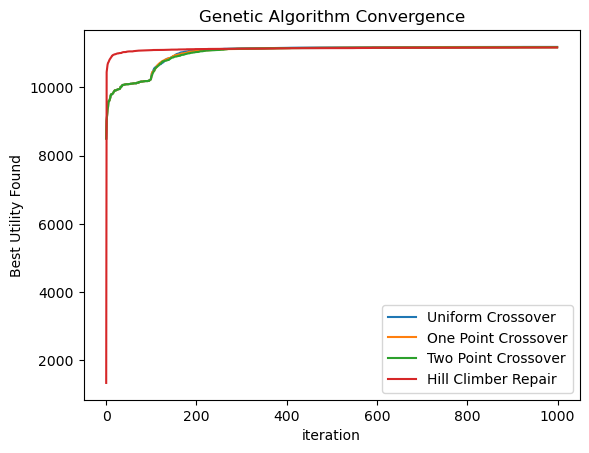

In [39]:
for name, (bestList, traces, solutions, times) in resultsGA.items():
    averageTrace = np.mean(traces, axis = 0)
    plt.plot(averageTrace, label = name)
plt.xlabel("iteration")
plt.ylabel("Best Utility Found")
plt.title("Genetic Algorithm Convergence")
plt.legend()
plt.show()

In [40]:
for budget in [1000, 5000, 20000]:
    ga = runExperimentGA(budget, capacities2, demands2, utilities2, modelsByRatio2, numRuns = 10)
    hc = runExperiment(capacities2, demands2, utilities2, modelsByRatio2, swap = True, repair = True, maxEvals = budget, numRuns = 10)
    print(f"budget {budget}: GA mean = {ga[0].mean():.0f}, HC mean = {hc[0].mean():.0f}")

budget 1000: GA mean = 11188, HC mean = 11166
budget 5000: GA mean = 11191, HC mean = 11188
budget 20000: GA mean = 11191, HC mean = 11188


PART 3

In [54]:
for name in ["Uniform Crossover", "One Point Crossover", "Hill Climber Repair"]:
    solutions = resultsGA[name][2]
    totalUsage = 100 * np.array([np.dot(demands2, individual) / capacities2 for individual in solutions])
    print(f"{name}: mean % of each capacity used = {np.round(totalUsage.mean(axis = 0), 1)}, lowest = {np.round(totalUsage.min(axis = 0),1)}")

Uniform Crossover: mean % of each capacity used = [ 84.5 100.   68.   59.8  67.3], lowest = [82.4 99.9 63.6 55.7 67.2]
One Point Crossover: mean % of each capacity used = [84.3 99.9 67.6 59.4 67. ], lowest = [81.8 99.4 63.6 55.6 65.5]
Hill Climber Repair: mean % of each capacity used = [ 84.3 100.   66.1  57.5  67.7], lowest = [81.8 99.6 63.6 55.6 66.2]


In [41]:
allModelCapacity = demands2.sum(axis=1) / capacities2
print("total demand over capacity for each capacity: ", np.round(allModelCapacity, 2))
print("mean demand per model over capacity: ", np.round(demands2.mean(axis = 1) / capacities2, 2))

total demand over capacity for each capacity:  [1.58 3.06 1.17 1.05 1.1 ]
mean demand per model over capacity:  [0.02 0.03 0.01 0.01 0.01]


In [43]:
def modelPrioritySort(utilities, storageReqs, storageMax, weighting):
    
    weightedDemand = (weighting[:, None] * storageReqs / storageMax[:, None]).sum(axis = 0)
    return list(np.argsort(-(utilities/weightedDemand)))
    

In [44]:
print(totalUsage.mean(axis = 0))
normalOrder = modelPrioritySort(utilities2, demands2, capacities2, np.ones(5))
priorities = totalUsage.mean(axis = 0)
weighting = priorities / priorities.mean()
weightedOrder = modelPrioritySort(utilities2, demands2, capacities2, weighting)
print(normalOrder)
print(weightedOrder)

[84.33968254 99.95454545 66.12121212 57.49369369 67.67222222]
[30, 62, 10, 0, 12, 11, 42, 6, 17, 49, 22, 4, 47, 84, 29, 69, 48, 85, 68, 41, 58, 15, 65, 61, 66, 34, 38, 55, 72, 75, 21, 53, 50, 59, 3, 18, 25, 73, 80, 60, 78, 32, 81, 70, 79, 8, 86, 87, 20, 9, 51, 74, 33, 57, 89, 24, 37, 52, 1, 14, 16, 5, 39, 40, 88, 54, 77, 82, 67, 27, 28, 13, 2, 7, 26, 76, 36, 23, 63, 31, 35, 46, 44, 43, 83, 71, 19, 56, 64, 45]
[62, 30, 0, 10, 6, 11, 12, 42, 17, 22, 4, 49, 47, 29, 84, 41, 69, 48, 85, 68, 65, 15, 61, 55, 38, 72, 66, 34, 58, 75, 21, 50, 18, 59, 53, 25, 60, 3, 73, 81, 8, 87, 32, 78, 86, 79, 51, 9, 70, 80, 33, 57, 74, 20, 89, 14, 24, 39, 1, 37, 77, 5, 52, 54, 16, 82, 40, 88, 67, 27, 13, 28, 2, 63, 23, 36, 26, 7, 76, 31, 46, 35, 44, 43, 71, 83, 19, 56, 64, 45]


In [45]:
fractionToRemove = np.maximum(1 - 1/allModelCapacity, 0.01)
weightingOptions = { "equal": np.ones(5),
                    "Usage Based": weighting,
                    "Oversubbed": allModelCapacity / allModelCapacity.mean(),
                    "Remaining": fractionToRemove/ fractionToRemove.mean()
                   }
rnd.seed(5)
randoms=[]
for i in range(1000):
    randoms.append(generateSolution(n2, 0.5))
base = modelPrioritySort(utilities2, demands2, capacities2, weightingOptions["equal"])
for name,weightMethod in weightingOptions.items():
    order = modelPrioritySort(utilities2, demands2, capacities2, weightMethod)
    correlation = np.corrcoef(np.argsort(base),np.argsort(order))[0,1]
    fixed = []
    for solution in randoms:
        fixed.append(repairSolution(solution, capacities2, demands2, order))
    utilityList = []
    for item in fixed:
        utilityList.append(np.dot(utilities2, item))
    utilityMean = np.mean(utilityList)
    changedList = []
    for solution, fixedSolution in zip(randoms,fixed):
        count = 0
        for positionSol, positionfixed in zip(solution, fixedSolution):
            if positionSol != positionfixed:
                count += 1
        changedList.append(count)
    changedMean = np.mean(changedList)
    print(f"{name:19s} weights = {np.round(weightMethod, 2)} rank correlation vs equal = {correlation:.4f}"
        f"utility after repair = {utilityMean:.0f} positions changed = {changedMean}")

equal               weights = [1. 1. 1. 1. 1.] rank correlation vs equal = 1.0000utility after repair = 8340 positions changed = 18.047
Usage Based         weights = [1.12 1.33 0.88 0.77 0.9 ] rank correlation vs equal = 0.9942utility after repair = 8383 positions changed = 17.553
Oversubbed          weights = [0.99 1.92 0.74 0.66 0.69] rank correlation vs equal = 0.9810utility after repair = 8454 positions changed = 17.351
Remaining           weights = [1.38 2.54 0.56 0.18 0.34] rank correlation vs equal = 0.9606utility after repair = 8463 positions changed = 17.267


In [47]:
overSubbedWeights = allModelCapacity / allModelCapacity.mean()
equalOrder = modelPrioritySort(utilities2, demands2, capacities2, np.ones(5))
overSubbedOrder = modelPrioritySort(utilities2, demands2, capacities2, overSubbedWeights)
print(equalOrder == modelsByRatio2)

True


In [48]:
budget = 1000
resultsPart3 = {}
resultsPart3 ["Equal Weighting"] = runExperimentGA (budget, capacities2, demands2, utilities2, equalOrder, numRuns = 100)
resultsPart3 ["Oversubbed Weighting"] = runExperimentGA (budget, capacities2, demands2, utilities2, overSubbedOrder, numRuns = 100)

In [49]:
bestFound = 0
for utility in resultsPart3.values():
    currentBest = utility[0].max()
    if currentBest > bestFound:
        bestFound = currentBest
aim = 0.9999 * bestFound
evaluationsNeeded = {}
for name, (bestList, traces, solutions, times) in resultsPart3.items():
    needed = []
    for trace in traces:
        achieved = np.where(trace >= aim)[0]
        if len(achieved) > 0:
            needed.append(achieved[0] + 1)
        else:
            needed.append(budget + 1)
    evaluationsNeeded[name] = np.array(needed)
for name, (bestList, traces, solutions, times) in resultsPart3.items():
    reachedCount = 0
    for evaluation in evaluationsNeeded[name]:
        if evaluation <= budget:
            reachedCount = reachedCount + 1
    meanResult = bestList.mean()
    stdResult = bestList.std()
    maxResult = bestList.max()
    minResult = bestList.min()
    totalRuns = len(bestList)
    medianEvaluations = np.median(evaluationsNeeded[name])
    meanBestSoFar = traces.mean()
    averageTime = times.mean()
    print(f"{name:20s}\nFinal: Mean = {meanResult:.0f}, std = {stdResult:.2f}, max = {maxResult:.1f}, min = {minResult:.1f}"
    f"\nReached Target in {reachedCount}/{totalRuns} runs, Median Evaluations = {medianEvaluations:.0f} trace mean = {meanBestSoFar:.0f}"
    f"\nTime Taken = {averageTime:.3f}s")

Equal Weighting     
Final: Mean = 11190, std = 4.98, max = 11191.0, min = 11165.0
Reached Target in 87/100 runs, Median Evaluations = 723 trace mean = 11034
Time Taken = 0.394s
Oversubbed Weighting
Final: Mean = 11191, std = 0.00, max = 11191.0, min = 11191.0
Reached Target in 100/100 runs, Median Evaluations = 410 trace mean = 11054
Time Taken = 0.389s


In [50]:
equal = resultsPart3["Equal Weighting"][0]
oversubbed = resultsPart3["Oversubbed Weighting"][0]

statistic, p = wilcoxon(equal, oversubbed)
print("Wilcoxon Statistic:", statistic)
print("p-value:", p)

Wilcoxon Statistic: 0.0
p-value: 0.0012052502554994481


In [51]:
equalEvals = evaluationsNeeded["Equal Weighting"]
oversubbedEvals = evaluationsNeeded["Oversubbed Weighting"]
statistic, p = wilcoxon(equalEvals, oversubbedEvals)
print("Wilcoxon Statistic:", statistic)
print("p-value:", p)

Wilcoxon Statistic: 175.0
p-value: 6.471727526440811e-16


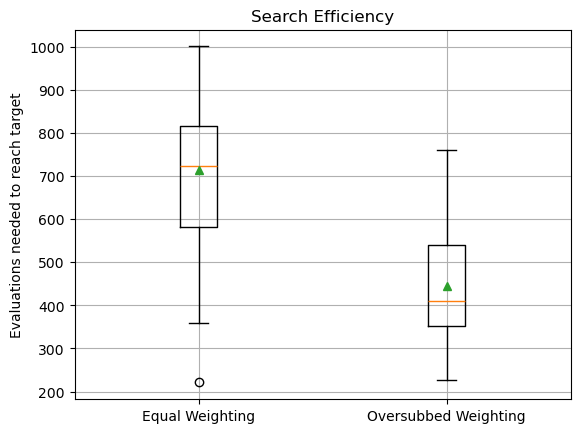

In [52]:
plt.boxplot(
            [equalEvals, oversubbedEvals], 
            tick_labels = ["Equal Weighting", "Oversubbed Weighting"], 
            showmeans = True
           )
plt.ylabel("Evaluations needed to reach target")
plt.title("Search Efficiency")
plt.grid()
plt.show()

In [53]:
for name, (bestList, traces, solutions, times) in resultsPart3.items():
    averageTrace = np.mean(traces, axis = 0)
    plt.plot(averageTrace, label = name)
plt.xlabel("iteration")
plt.ylabel("Best Utility Found")
plt.title("Equal vs Oversubbed")
plt.axhline(y=target, color="green", linestyle="--", label= "99.99% Target")
plt.legend()
plt.show()

NameError: name 'target' is not defined

[1]P.C. Chu and J.E. Beasley A generic Algorithm for the Multidimensional Knapsack Problem Journal of Heuristics vol.4 pg63 - 86 